# 04 — Anomaly detection and explainability
Real anomaly labels are absent. This notebook demonstrates residual flags, reproducible synthetic spikes and feature reliance.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src' / 'wattwise').exists():
    PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))


In [2]:
import matplotlib.pyplot as plt
import json
import pandas as pd
from wattwise.data_loader import load_data
from wattwise.preprocessing import clean_data
from wattwise.feature_engineering import make_features,chronological_split
from wattwise.inference import load_bundle,predict_next
from wattwise.config import ARTIFACTS,REPORTS
from wattwise.anomaly_detection import residual_threshold,residual_flags,inject_spikes,synthetic_metrics

df,_=clean_data(load_data()); X,y,t=make_features(df); s=chronological_split(X,y,t)
Xtr,ytr,_=s['train']; Xv,yv,_=s['validation']; Xte,yte,_=s['test']
bundle=load_bundle(ARTIFACTS/'wattwise_bundle.joblib')
def selected_predict(frame): return predict_next(bundle,frame)
print('Loaded selected model:',bundle['selected_model'])

Loaded selected model: Voting (top 3)


In [3]:
pt=selected_predict(Xte)
cutoff=bundle['threshold']
flags_test=residual_flags(yte,pt,cutoff)
cutoff,int(flags_test['flag'].sum())

(284.121956582817, 38)

In [4]:
synthetic,labels,indices=inject_spikes(yte,seed=42)
residual_scores=abs(synthetic-pt)
indices[:10],synthetic_metrics(labels,residual_scores,cutoff)

(array([128, 186, 198, 248, 257, 268, 272, 371, 453, 482]),
 {'precision': 0.02564102564102564,
  'recall': 0.016666666666666666,
  'f1': 0.020202020202020204,
  'confusion_matrix': [[2841, 38], [59, 1]],
  'pr_auc': 0.26273048855397624,
  'threshold': 284.121956582817})

In [5]:
importance=pd.read_csv(REPORTS/'metrics'/'feature_importance.csv')
assert importance['selected_model'].iloc[0]==bundle['selected_model']
importance.head(15)

,feature,importance,importance_std,baseline_mae,run_id,reference_split,selected_model
0,appliances_current,37.499220,0.194665,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
1,appliances_change_1,4.004020,0.080708,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
2,appliances_lag_1,0.991560,0.029827,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
3,hour_sin,0.624911,0.022181,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
4,appliances_roll_mean_12,0.450296,0.008376,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
5,RH_3_change_1,0.371211,0.014773,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
6,appliances_roll_std_3,0.299166,0.008204,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
7,lights,0.216251,0.004405,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
8,T9,0.215962,0.015443,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)
9,appliances_roll_mean_3,0.209333,0.008683,25.062252,55004ee9-e3d3-433c-9528-6e2227d2b7d8,training,Voting (top 3)


In [6]:
iso=bundle['isolation_forest']
iso_scores=-iso.score_samples(Xte)
saved_anomaly=json.loads((REPORTS/'metrics'/'anomaly_evaluation.json').read_text())
iso_cut=saved_anomaly['isolation_forest_training_score_quantile_99']
iso_cut,int((iso_scores>iso_cut).sum())

(0.5629599865479988, 145)

Isolation Forest can be fit using `fit_isolation_forest(Xtr)`. Synthetic labels do not establish natural-world detection accuracy. Feature importance explains model reliance, not causation. A flag does not prove waste or identify a fault.

## Residual behavior over time

Residuals are observed minus expected. Positive values mean actual consumption exceeded the forecast; negative values mean it was lower. The loaded model is the persisted validation-selected predictor; the absolute residual cutoff is calibrated from validation residuals only and loaded from the same run bundle.

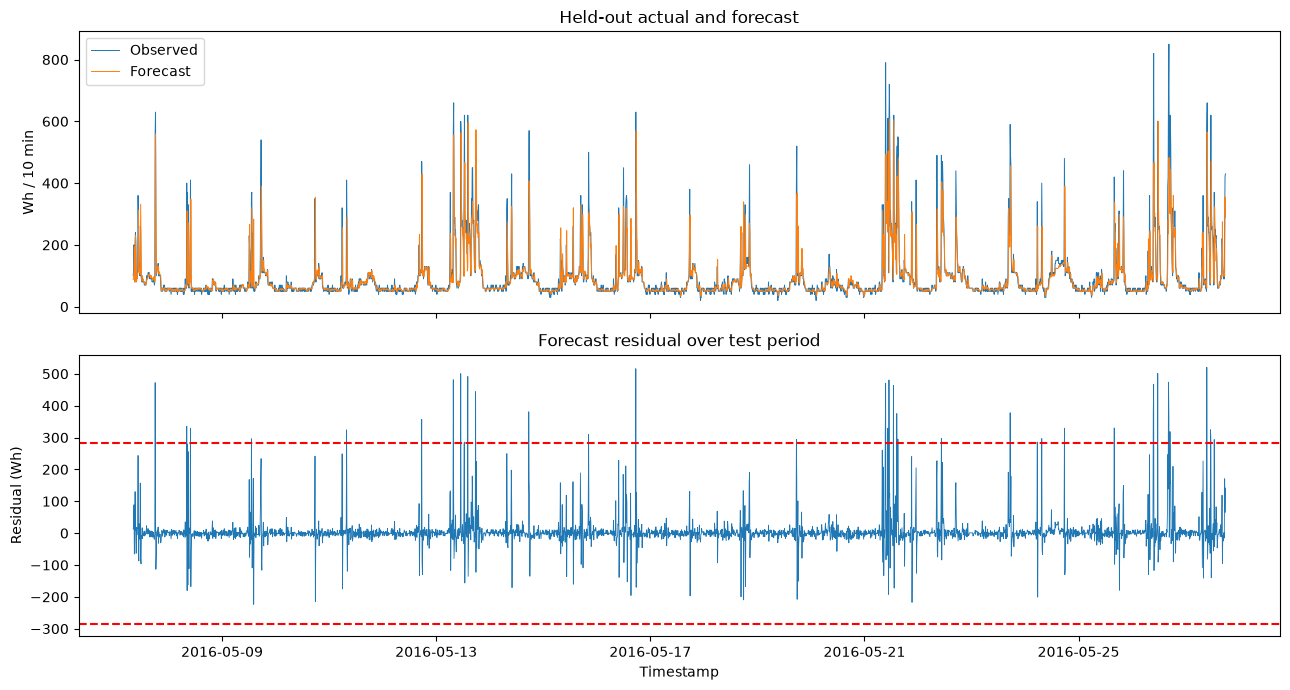

In [7]:
residual=yte.to_numpy()-pt
fig,ax=plt.subplots(2,1,figsize=(13,7),sharex=True)
ax[0].plot(s['test'][2],yte,label='Observed',lw=.7); ax[0].plot(s['test'][2],pt,label='Forecast',lw=.7); ax[0].set(ylabel='Wh / 10 min',title='Held-out actual and forecast'); ax[0].legend()
ax[1].plot(s['test'][2],residual,lw=.6); ax[1].axhline(cutoff,color='red',ls='--'); ax[1].axhline(-cutoff,color='red',ls='--'); ax[1].set(xlabel='Timestamp',ylabel='Residual (Wh)',title='Forecast residual over test period'); plt.tight_layout()


## Residual distribution and candidate events

The empirical cutoff marks unusual error magnitudes relative to validation. This threshold produces candidates, not verified anomalies or waste labels.

{'cutoff_wh': 284.121956582817,
 'candidate_count': 38,
 'high_consumption_candidates': 38}

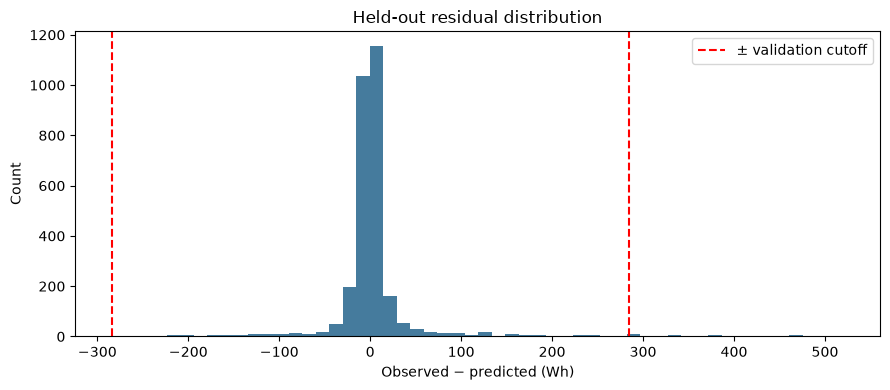

In [8]:
flags=residual_flags(yte,pt,cutoff)
fig,ax=plt.subplots(figsize=(9,4)); ax.hist(residual,bins=50,color='#457b9d'); ax.axvline(cutoff,color='red',ls='--',label='± validation cutoff'); ax.axvline(-cutoff,color='red',ls='--'); ax.set(title='Held-out residual distribution',xlabel='Observed − predicted (Wh)',ylabel='Count'); ax.legend(); plt.tight_layout()
{'cutoff_wh':cutoff,'candidate_count':int(flags['flag'].sum()),'high_consumption_candidates':int(flags['high_consumption'].sum())}


## Isolation Forest scores

Isolation Forest is fitted only on training feature vectors. Its score is a relative outlier ranking, not an anomaly probability. The 99th percentile of training outlier scores is used here for a transparent demonstration.

In [9]:
iso_train=-iso.score_samples(Xtr); iso_test=-iso.score_samples(Xte)
{'training_score_cutoff':iso_cut,'test_candidates':int((iso_test>iso_cut).sum())}

{'training_score_cutoff': 0.5629599865479988, 'test_candidates': 145}

## Compare synthetic detector recovery

Ground truth exists only for injected spikes in a separate copy of the test target. Natural test observations remain unlabeled. Precision/recall and PR-AUC use the recorded continuous detector scores and thresholds. They characterize only this fixed-seed injection strength, not naturally occurring anomalies.

In [10]:
syn_iso_X=Xte.copy(); syn_iso_X['appliances_current']=synthetic
syn_iso_score=-iso.score_samples(syn_iso_X)
{'residual_detector':synthetic_metrics(labels,residual_scores,cutoff),'isolation_forest_detector':synthetic_metrics(labels,syn_iso_score,iso_cut),'injected_indices_count':len(indices)}

{'residual_detector': {'precision': 0.02564102564102564,
  'recall': 0.016666666666666666,
  'f1': 0.020202020202020204,
  'confusion_matrix': [[2841, 38], [59, 1]],
  'pr_auc': 0.26273048855397624,
  'threshold': 284.121956582817},
 'isolation_forest_detector': {'precision': 0.03496503496503497,
  'recall': 0.08333333333333333,
  'f1': 0.04926108374384237,
  'confusion_matrix': [[2741, 138], [55, 5]],
  'pr_auc': 0.022035461261068853,
  'threshold': 0.5629599865479988},
 'injected_indices_count': 60}

## Local explanation with SHAP

The optional permutation SHAP explanation shows how input features shift one forecast relative to a background sample. If SHAP cannot run with the installed model/library combination, use the trained global importance and state the fallback. Attributions explain model behavior, not causes.

In [11]:
from wattwise.explainability import local_shap_values
local,shap_error=local_shap_values(selected_predict,Xtr.sample(min(500,len(Xtr)),random_state=42),Xte.iloc[[0]])
if shap_error: print(shap_error)
else: display(local.head(15))

,feature,contribution,abs_contribution
27,appliances_current,8.381278,8.381278
28,appliances_lag_1,3.756911,3.756911
42,appliances_change_1,-3.360612,3.360612
58,hour_sin,-3.134842,3.134842
35,appliances_roll_std_3,-1.653756,1.653756
48,T3_change_1,1.619490,1.619490
55,hour,-1.102344,1.102344
59,hour_cos,0.987784,0.987784
38,appliances_roll_mean_12,0.603138,0.603138
30,appliances_lag_3,0.520280,0.520280


## Interpretation and limitations

Separate four statements: (1) a statistical residual crossed a cutoff; (2) observed use was higher than expected; (3) the event may merit waste investigation; (4) waste is confirmed. This dataset supports only the first two. Confirmation needs labels, context, or an intervention measurement. Regression forecast quality is reported with MAE, RMSE and R²; classification accuracy is not defined for this target. Synthetic injection recovery is specific to the injected spike design and must not be presented as natural anomaly accuracy.

In [12]:
print('Unlabeled real test rows:',len(yte),'| synthetic injected rows:',int(labels.sum()))
print('No supervised accuracy is reported for naturally occurring anomalies.')


Unlabeled real test rows: 2939 | synthetic injected rows: 60
No supervised accuracy is reported for naturally occurring anomalies.
